**Bank Customer Churn Analysis**

---
Identifying Customer Segments with Higher Churn Rates Using Python

Project type: Exploratory Data Analysis (EDA)

Tools: Python, Pandas, NumPy, Matplotlib, Seaborn

Dataset: Bank Customer Churn — 10,000 customer records

**1. Project Overview**

---
Customer churn occurs when customers stop using a company's products or services. In banking, understanding which customer groups have higher churn rates can help the bank prioritize retention efforts.

This project explores customer churn patterns using descriptive statistics, customer segmentation, and visual analysis. The analysis focuses on identifying groups with comparatively high churn rates and translating the findings into practical business recommendations.

Important: This is an exploratory analysis. The observed relationships do not establish causation and should not be interpreted as proof that a particular characteristic causes customers to leave.

**2. Business Understanding**

---
Business problem
The bank needs to understand how churn is distributed across customer characteristics so that retention initiatives can be prioritized.
Objectives
1. Understand the structure and quality of the customer dataset.
2. Measure the overall proportion of customers who churned.
3. Compare churn rates across geography, gender, account activity, and age groups.
4. Explore how customer balance differs between retained and churned customers.
5. Formulate data-informed recommendations for customer retention.
Business questions
- What proportion of customers have churned?
- Do churn rates differ by geography and gender?
- Is churn more common among inactive customers?
- Which age groups have relatively higher churn rates?
- How does the average account balance differ between retained and churned customers?

**3. Import Libraries**

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.__version__


'2.2.3'

**4. Load Dataset**

In [32]:
url_csv = "https://raw.githubusercontent.com/abeliyasya/churn_analysis/refs/heads/main/Churn.csv"

df_raw = pd.read_csv(url_csv,sep=";")
df_raw.shape


(10000, 11)

**5. Data Understanding**

In [33]:
print(df_raw.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  object 
 2   Gender           10000 non-null  object 
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 859.5+ KB
None


**6. Data Quality Assessment**

In [34]:
print("--- INFO DATASET ---")
print(f"Jumlah Baris & Kolom: {df_raw.shape}")
print("\nJumlah Missing Value per Kolom:")
print(df_raw.isnull().sum())
print(df_raw.duplicated().sum())
print((df_raw['Balance'] == 0).sum())

--- INFO DATASET ---
Jumlah Baris & Kolom: (10000, 11)

Jumlah Missing Value per Kolom:
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
0
3617


In [35]:
df_raw.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**7. Overall Churn Analysis**

In [36]:
print("\n--- DISTRIBUSI TARGET (CHURN VS RETAINED) ---")
churn_counts = df_raw['Exited'].value_counts(normalize=True) * 100
print(f"Retained (0): {churn_counts[0]:.2f}%")
print(f"Churned  (1): {churn_counts[1]:.2f}%")


--- DISTRIBUSI TARGET (CHURN VS RETAINED) ---
Retained (0): 79.63%
Churned  (1): 20.37%


In [37]:
# Aggregation Analysis (Eksplorasi Risiko Churn)

# A. Churn Rate berdasarkan Negara & Gender
geo_gender_analysis = df_raw.groupby(['Geography', 'Gender']).agg(
    Total_Customers=('Exited', 'count'),
    Churned_Customers=('Exited', 'sum'),
    Churn_Rate_Pct=('Exited', lambda x: round(x.mean() * 100, 2)),
    Avg_Balance=('Balance', 'mean')
).reset_index()

print("\n--- CHURN RATE BY GEOGRAPHY & GENDER ---")
print(geo_gender_analysis)


--- CHURN RATE BY GEOGRAPHY & GENDER ---
  Geography  Gender  Total_Customers  Churned_Customers  Churn_Rate_Pct  \
0    France  Female             2261                460           20.34   
1    France    Male             2753                350           12.71   
2   Germany  Female             1193                448           37.55   
3   Germany    Male             1316                366           27.81   
4     Spain  Female             1089                231           21.21   
5     Spain    Male             1388                182           13.11   

     Avg_Balance  
0   60322.670159  
1   63546.284875  
2  119145.966471  
3  120259.668222  
4   59862.092534  
5   63352.833746  


**8. Geography & Gender**

Text(0.5, 0, 'Geography')

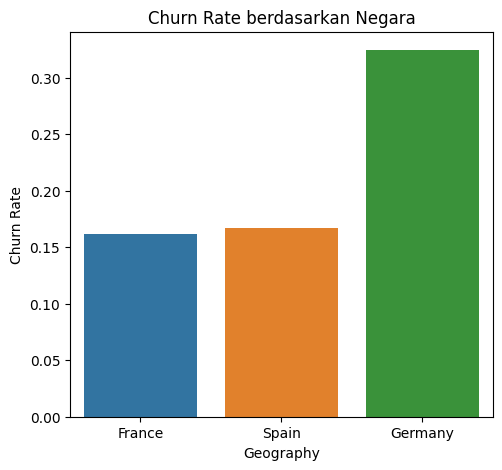

In [38]:
plt.figure(figsize=(12, 5))

# Churn Rate berdasarkan Geography
plt.subplot(1, 2, 1)
sns.barplot(
    data=df_raw,
    x='Geography',
    y='Exited',
    errorbar=None,
    hue='Geography',
    legend=False
)
plt.title('Churn Rate berdasarkan Negara')
plt.ylabel('Churn Rate')
plt.xlabel('Geography')



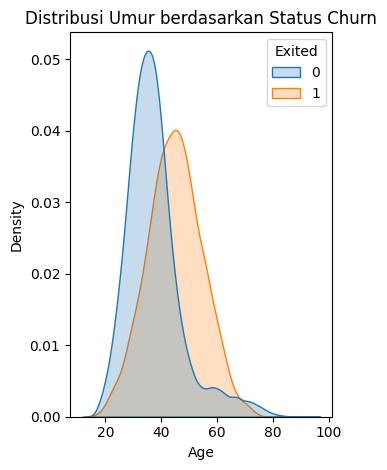

In [39]:
# Distribusi umur berdasarkan status churn
plt.subplot(1, 2, 2)
sns.kdeplot(
    data=df_raw,
    x='Age',
    hue='Exited',
    common_norm=False,
    fill=True
)
plt.title('Distribusi Umur berdasarkan Status Churn')

plt.tight_layout()
plt.show()

**9. Membership Activity**

In [40]:
# B. Churn Rate berdasarkan Keaktifan (IsActiveMember)
active_analysis = df_raw.groupby('IsActiveMember').agg(
    Total=('Exited', 'count'),
    Churn_Rate_Pct=('Exited', lambda x: round(x.mean() * 100, 2))
)
print("\n--- CHURN RATE BY MEMBER ACTIVITY ---")
print(active_analysis)



--- CHURN RATE BY MEMBER ACTIVITY ---
                Total  Churn_Rate_Pct
IsActiveMember                       
0                4849           26.85
1                5151           14.27


In [41]:

df_raw["Gender"].unique()

array(['Female', 'Male'], dtype=object)

**10. Age Segmentation**

In [42]:
df_raw["Age_Group"] = pd.cut(
    df_raw["Age"], bins=[0, 29, 39, 49, 120],
    labels=["<30", "30-39", "40-49", "50+"]
)
summary = df_raw.groupby("Age_Group", observed=True).agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate_Pct=("Exited", lambda x: round(x.mean() * 100, 2)),
    Avg_Balance=("Balance", lambda x: round(x.mean(), 2))
).reset_index().sort_values("Churn_Rate_Pct", ascending=False)
print(summary)

  Age_Group  Total_Customers  Churned_Customers  Churn_Rate_Pct  Avg_Balance
3       50+             1395                634           45.45     80429.11
2     40-49             2618                806           30.79     78479.24
1     30-39             4346                473           10.88     75071.80
0       <30             1641                124            7.56     73698.72


**11. Balance Analysis**

In [43]:
balance_summary = df_raw.groupby('Exited').agg(
    Total_Nasabah=('Balance', 'count'),
    Avg_Balance=('Balance', lambda x: round(x.mean(), 2)),
    Median_Balance=('Balance', lambda x: round(x.median(), 2)),
    Total_Volume=('Balance', lambda x: round(x.sum(), 2))
).reset_index()

print(balance_summary)

   Exited  Total_Nasabah  Avg_Balance  Median_Balance  Total_Volume
0       0           7963     72745.30        92072.68  5.792708e+08
1       1           2037     91108.54       109349.29  1.855881e+08


**12. Key Findings**

---
1. Overall churn: 20.37% of the 10,000 customers were recorded as churned; 79.63% were retained.
2. Geography: Germany showed the highest churn rates in both gender groups in the aggregation. Germany's female segment had a 37.55% churn rate and its male segment had a 27.81% churn rate.
3. Gender : The churn rate for women is higher than for men in all three countries (France: 20.3% vs. 12.7%; Spain: 21.2% vs. 13.1%; Germany: 37.6% vs. 27.8%).
4. Membership activity: inactive customers had a 26.85% churn rate, compared with 14.27% among active customers in the aggregation.
5. Balance: churned customers had a higher average balance (91,108.54) than retained customers (72,745.30) in the aggregation.
6. Age: the original age segmentation showed higher churn rates in older groups. However, its bin boundaries did not precisely match the labels. The corrected age-segmentation results before quoting exact percentages.


**13. Business Recommendations**

---
The recommendations below are hypotheses for retention actions. They should be tested with additional customer-level and campaign data before implementation.
1. Prioritize retention analysis for higher-churn segments
Investigate customers in segments that show higher churn rates, particularly the Germany market in the original analysis. Review customer feedback, service issues, product fit, and competitor offers before deciding on an intervention.
2. Monitor declining customer activity
Inactive customers showed a higher churn rate in the original analysis. Consider monitoring reductions in transaction frequency or digital engagement and testing targeted re-engagement campaigns.
3. Review the experience of older customers
The original age segmentation indicated higher churn among older age groups. Evaluate service accessibility, branch support, digital banking usability, and the suitability of existing products for these customers.
4. Protect relationships with customers holding higher balances
Churned customers had a higher average balance in the original analysis. Consider a more detailed value analysis that includes product holdings, profitability, tenure, and service costs. Balance alone is not enough to estimate revenue loss.

**14. Limitations**

---
- The analysis is descriptive and does not establish causal relationships.
- The dataset does not provide customer feedback, reasons for leaving, transaction history, or campaign exposure.
- Account balance is not the same as revenue or profit.
- Some customer groups may have different sample sizes; percentages should be interpreted alongside customer counts.
- The age-segmentation results must be recalculated using the corrected age boundaries before final publication.

**15. Conclusion**

---
This exploratory analysis identifies differences in customer churn across geography, gender, membership activity, age, and account balance. The original results indicate that churn is not evenly distributed across customer groups: inactive customers and certain demographic/geographic segments have higher observed churn rates.

These findings can help the bank decide where to investigate customer experience and retention opportunities first. However, the analysis does not establish why customers churn. Further work could combine transaction behavior, customer feedback, product usage, and profitability data to build a more complete retention strategy.